# Quiz
### Guideline
1. Please submit the file via Google Classroom.
2. File name convention is MSA38DN_\<Your full name\>\_classQuiz04
3. Provide your personal information in the next block.

### Student information
Full name: Bùi Ngọc Bảo Trân

Student ID: 25MS33062

Group: 2

In [1]:
import os
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

import requests

# define your addition imported libraries below

In [2]:
def download_input_data(url):
  print(f"Downloading from {url}")
  # Download the image.
  response = requests.get(url, stream=True)
  response.raise_for_status()

  # Read the image data from the response
  image_data = np.asarray(bytearray(response.content), dtype="uint8")

  # Decode the image using OpenCV
  img_gray = cv.imdecode(image_data, cv.IMREAD_GRAYSCALE)

  return img_gray

# Questions
Using the input image from ClassQuiz2, complete the following tasks:

1. Apply four different spatial kernels of your choice and display the four output images.

2. Apply a Sobel filter and display the result.

3. Apply a high-pass filter (HPF) and display the result.

4. Apply a blurring (low-pass) kernel and a sharpening kernel. Display both output images.

5. Re-run tasks (2) and (3) using the blurred and sharpened images from task (4) as inputs. Display the resulting images.

6. Compare the outputs from (2) and (3) with the ones from (5). Explain the similarities and differences.



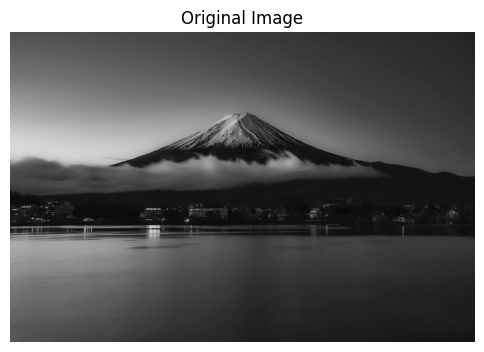

In [ ]:
download_url = "https://i.pinimg.com/1200x/ab/53/ca/ab53cab7e9784f2f5794f96cee7d5f1d.jpg"

response = requests.get(download_url, stream=True)
response.raise_for_status()

image_data = np.asarray(bytearray(response.content), dtype="uint8")

img_gray = cv.imdecode(image_data, cv.IMREAD_GRAYSCALE)

# Display original image
plt.figure(figsize=(6,6))
plt.imshow(img_gray, cmap='gray')
plt.title("Original Image")
plt.axis('off')
plt.show()

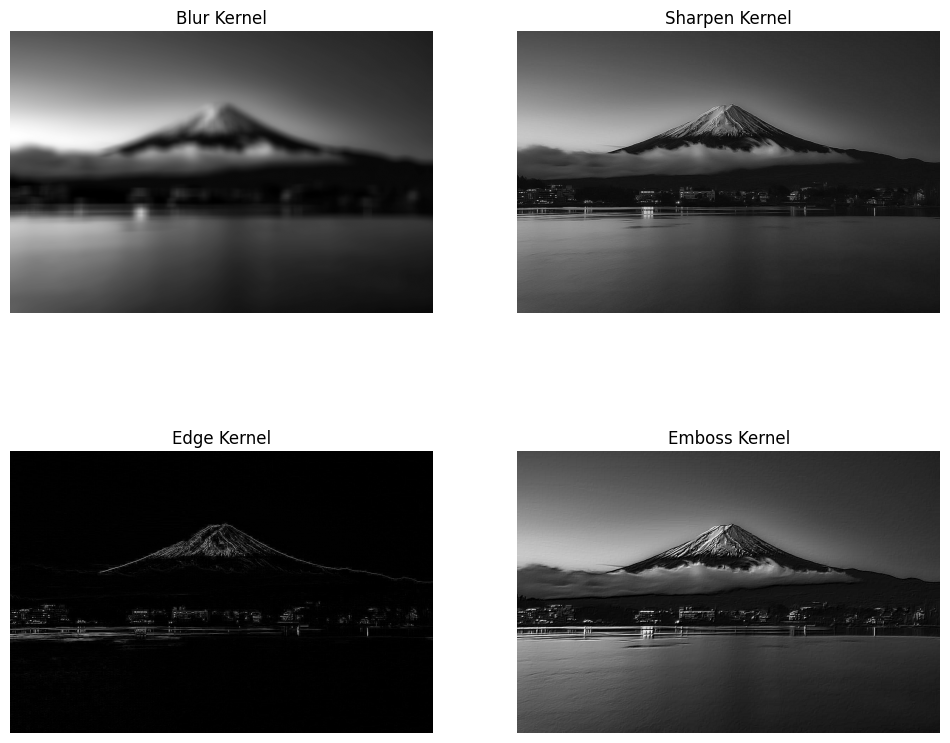

In [23]:
# 1. Apply four different spatial kernels of your choice and display the four output images.

# Blur kernel
kernel_blur = np.ones((25,25)) / (25*25)

# Sharpen kernel
kernel_sharpen = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

# Edge kernel
kernel_edge = np.array([
    [-1, -1, -1],
    [-1, 8, -1],
    [-1, -1, -1]
])

# Emboss kernel
kernel_emboss = np.array([
    [-2, -1, 0],
    [-1, 1, 1],
    [0, 1, 2]
])

# Apply kernels
img_blur = cv.filter2D(img_gray, -1, kernel_blur)
img_sharpen = cv.filter2D(img_gray, -1, kernel_sharpen)
img_edge = cv.filter2D(img_gray, -1, kernel_edge)
img_emboss = cv.filter2D(img_gray, -1, kernel_emboss)

# Display results
plt.figure(figsize=(12,10))

plt.subplot(2,2,1)
plt.imshow(img_blur, cmap='gray')
plt.title("Blur Kernel")
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(img_sharpen, cmap='gray')
plt.title("Sharpen Kernel")
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(img_edge, cmap='gray')
plt.title("Edge Kernel")
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(img_emboss, cmap='gray')
plt.title("Emboss Kernel")
plt.axis('off')

plt.show()

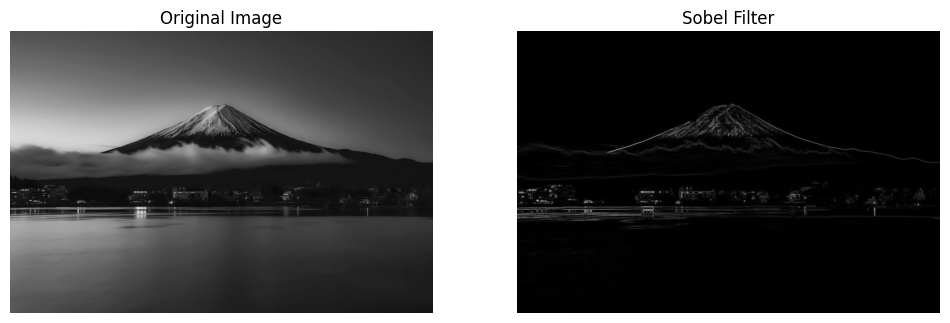

In [24]:
# 2. Apply a Sobel filter and display the result.

target_image = img_gray

# Sobel X kernel
sobel_x_kernel = np.array([
    [1, 0, -1],
    [2, 0, -2],
    [1, 0, -1]
])

# Sobel Y kernel
sobel_y_kernel = np.array([
    [1, 2, 1],
    [0, 0, 0],
    [-1, -2, -1]
])

# Apply Sobel kernels
sobel_x = cv.filter2D(target_image, cv.CV_64F, sobel_x_kernel)
sobel_y = cv.filter2D(target_image, cv.CV_64F, sobel_y_kernel)

# Combine X and Y results
sobel_result = np.sqrt(sobel_x**2 + sobel_y**2)

# Display results
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(target_image, cmap='gray')
plt.title("Original Image")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(sobel_result, cmap='gray')
plt.title("Sobel Filter")
plt.axis('off')

plt.show()

C:\Users\bngbtran\AppData\Local\Temp\ipykernel_13816\642397351.py:23: RuntimeWarning: divide by zero encountered in log
  magnitude_spectrum = 20 * np.log(np.abs(fshift_hpf))


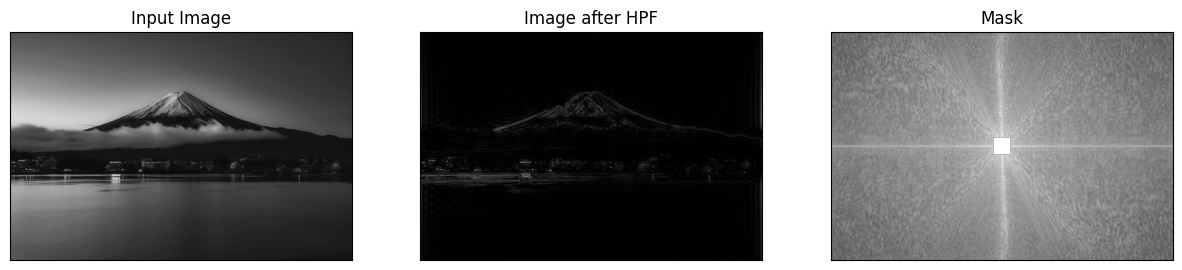

In [30]:
# 3. Apply a high-pass filter (HPF) and display the result.

# FFT transform
f = np.fft.fft2(img_gray)
fshift = np.fft.fftshift(f)

# Create HPF mask
rows, cols = img_gray.shape
crow, ccol = rows//2, cols//2

mask = np.ones((rows, cols), np.uint8)
mask[crow-30:crow+30, ccol-30:ccol+30] = 0

# Apply mask
fshift_hpf = fshift * mask

# Inverse FFT
f_ishift = np.fft.ifftshift(fshift_hpf)
img_hpf = np.fft.ifft2(f_ishift)
img_hpf = np.abs(img_hpf)

# Magnitude spectrum
magnitude_spectrum = 20 * np.log(np.abs(fshift_hpf))

# Display results
plt.figure(figsize=(15,15))

plt.subplot(131)
plt.imshow(img_gray, cmap='gray')
plt.title("Input Image")
plt.xticks([])
plt.yticks([])

plt.subplot(132)
plt.imshow(img_hpf, cmap='gray')
plt.title("Image after HPF")
plt.xticks([])
plt.yticks([])

plt.subplot(133)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("Mask")
plt.xticks([])
plt.yticks([])

plt.show()

C:\Users\bngbtran\AppData\Local\Temp\ipykernel_13816\992985913.py:25: RuntimeWarning: divide by zero encountered in log
  magnitude_spectrum_lpf = 20 * np.log(np.abs(f_fshift))


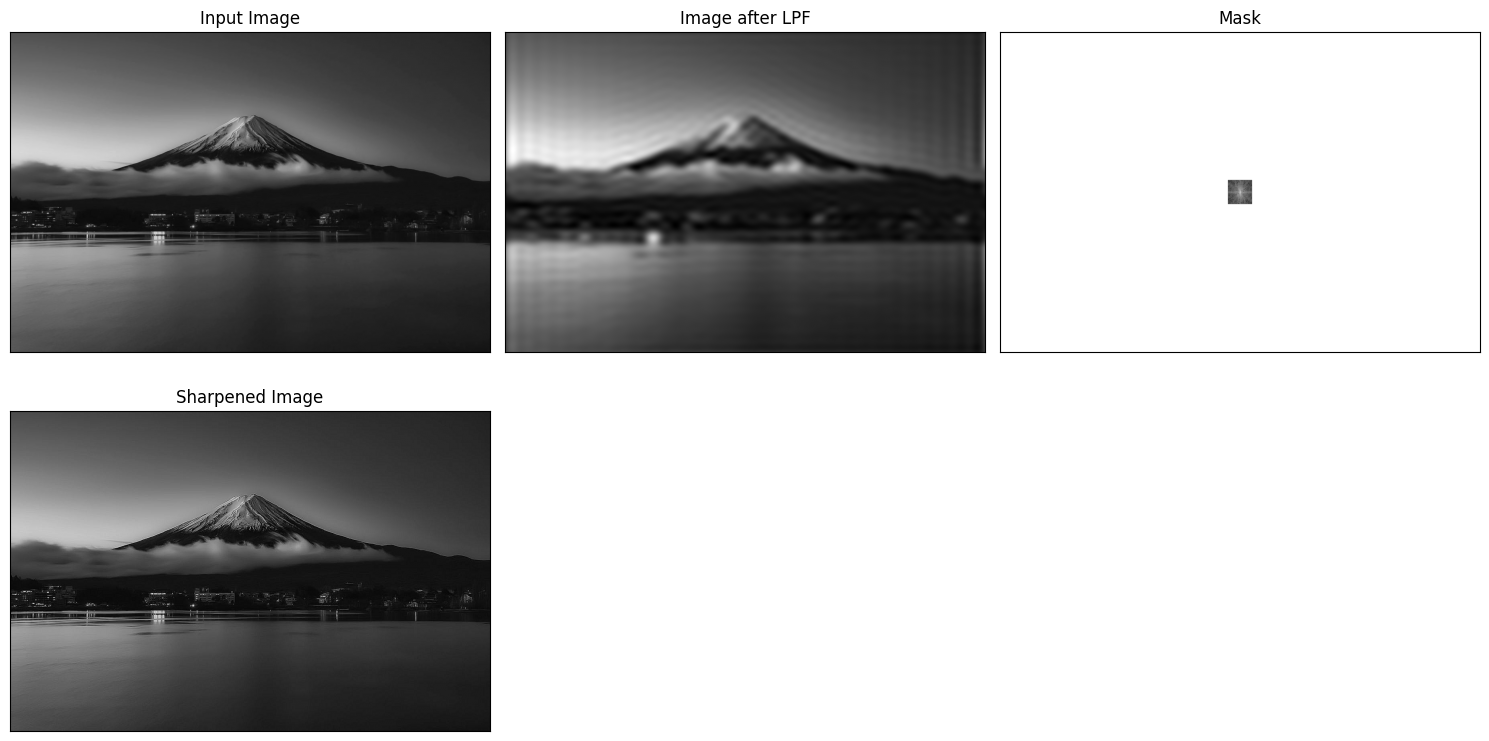

In [32]:
# 4. Apply a blurring (low-pass) kernel and a sharpening kernel. Display both output images.

# FFT transform
f = np.fft.fft2(img_gray)
fshift = np.fft.fftshift(f)

# Create LPF mask
rows, cols = img_gray.shape
crow, ccol = rows//2 , cols//2

mask = np.zeros((rows, cols), np.uint8)

# Keep low-frequency area in the center
mask[crow-30:crow+30, ccol-30:ccol+30] = 1

# Apply mask
f_fshift = fshift * mask

# Inverse FFT
f_ishift = np.fft.ifftshift(f_fshift)
blurred_img = np.fft.ifft2(f_ishift)
blurred_img = np.abs(blurred_img)

# Magnitude spectrum
magnitude_spectrum_lpf = 20 * np.log(np.abs(f_fshift))

# Sharpen kernel
sharpen_kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

# Apply sharpen kernel
sharpened_img = cv.filter2D(img_gray, -1, sharpen_kernel)

# Display results
plt.figure(figsize=(15,8))

# Original image
plt.subplot(231)
plt.imshow(img_gray, cmap='gray')
plt.title("Input Image")
plt.xticks([])
plt.yticks([])

# LPF image
plt.subplot(232)
plt.imshow(blurred_img, cmap='gray')
plt.title("Image after LPF")
plt.xticks([])
plt.yticks([])

# LPF spectrum
plt.subplot(233)
plt.imshow(magnitude_spectrum_lpf, cmap='gray')
plt.title("Mask")
plt.xticks([])
plt.yticks([])

# Sharpen image
plt.subplot(234)
plt.imshow(sharpened_img, cmap='gray')
plt.title("Sharpened Image")
plt.xticks([])
plt.yticks([])

plt.tight_layout()
plt.show()

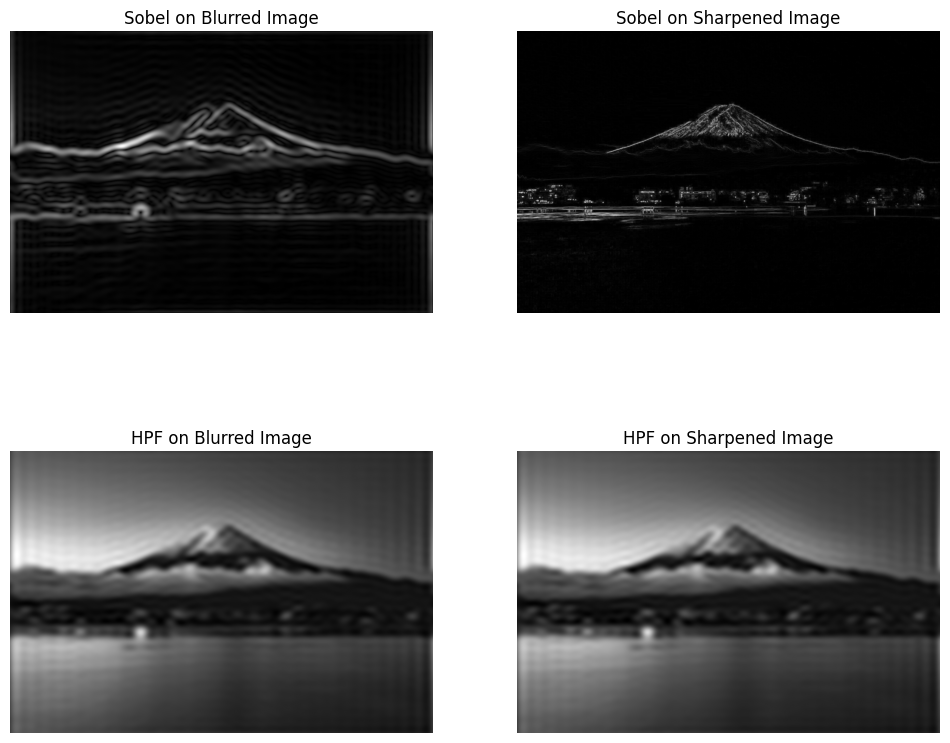

In [27]:
# 5. Re-run tasks (2) and (3) using the blurred and sharpened images from task (4) as inputs.

# Sobel on blurred image
sobel_blur_x = cv.Sobel(blurred_img, cv.CV_64F, 1, 0, ksize=3)
sobel_blur_y = cv.Sobel(blurred_img, cv.CV_64F, 0, 1, ksize=3)

sobel_blur = np.sqrt(sobel_blur_x**2 + sobel_blur_y**2)

# Sobel on sharpened image
sobel_sharp_x = cv.Sobel(sharpened_img, cv.CV_64F, 1, 0, ksize=3)
sobel_sharp_y = cv.Sobel(sharpened_img, cv.CV_64F, 0, 1, ksize=3)

sobel_sharp = np.sqrt(sobel_sharp_x**2 + sobel_sharp_y**2)

# HPF on blurred image
f_blur = np.fft.fft2(blurred_img)
fshift_blur = np.fft.fftshift(f_blur)

fshift_blur_hpf = fshift_blur * mask

f_ishift_blur = np.fft.ifftshift(fshift_blur_hpf)
img_hpf_blur = np.fft.ifft2(f_ishift_blur)
img_hpf_blur = np.abs(img_hpf_blur)

# HPF on sharpened image
f_sharp = np.fft.fft2(sharpened_img)
fshift_sharp = np.fft.fftshift(f_sharp)

fshift_sharp_hpf = fshift_sharp * mask

f_ishift_sharp = np.fft.ifftshift(fshift_sharp_hpf)
img_hpf_sharp = np.fft.ifft2(f_ishift_sharp)
img_hpf_sharp = np.abs(img_hpf_sharp)

# Display results
plt.figure(figsize=(12,10))

plt.subplot(2,2,1)
plt.imshow(sobel_blur, cmap='gray')
plt.title("Sobel on Blurred Image")
plt.axis('off')

plt.subplot(2,2,2)
plt.imshow(sobel_sharp, cmap='gray')
plt.title("Sobel on Sharpened Image")
plt.axis('off')

plt.subplot(2,2,3)
plt.imshow(img_hpf_blur, cmap='gray')
plt.title("HPF on Blurred Image")
plt.axis('off')

plt.subplot(2,2,4)
plt.imshow(img_hpf_sharp, cmap='gray')
plt.title("HPF on Sharpened Image")
plt.axis('off')

plt.show()

In [35]:
# 6. Compare the outputs from (2) and (3) with the ones from (5). Explain the similarities and differences.

print("Comparison between original Sobel/HPF and processed images:")
print()

print("1. Blurred images:")
print("- Edges become smoother and less detailed.")
print("- Sobel and HPF results contain less noise.")
print("- Some fine edges disappear after blurring.")
print()

print("2. Sharpened images:")
print("- Edges become clearer and stronger.")
print("- Sobel and HPF highlight more details.")
print("- Noise and texture are also enhanced.")
print()

print("3. Similarities:")
print("- Both Sobel and HPF focus on edge and high-frequency information.")
print("- Both methods highlight object boundaries.")
print()

print("4. Differences:")
print("- Sobel works in spatial domain using gradients.")
print("- HPF works in frequency domain using FFT.")
print("- HPF usually preserves more fine high-frequency details.")

Comparison between original Sobel/HPF and processed images:

1. Blurred images:
- Edges become smoother and less detailed.
- Sobel and HPF results contain less noise.
- Some fine edges disappear after blurring.

2. Sharpened images:
- Edges become clearer and stronger.
- Sobel and HPF highlight more details.
- Noise and texture are also enhanced.

3. Similarities:
- Both Sobel and HPF focus on edge and high-frequency information.
- Both methods highlight object boundaries.

4. Differences:
- Sobel works in spatial domain using gradients.
- HPF works in frequency domain using FFT.
- HPF usually preserves more fine high-frequency details.
